# Модульна контрольна робота № 2

## Вирівнювання зображення документа
Використовую фотографію та кути документа з попередньої МКР. Порівнюю афінні перетворення і гомографію для усунення перспективного спотворення.

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

plt.rcParams["figure.figsize"] = (10, 6)

### 1. Початкове зображення
Завантажую документ і перетворюю кольори з BGR у RGB для правильного відображення. Створюю також зображення у відтінках сірого.

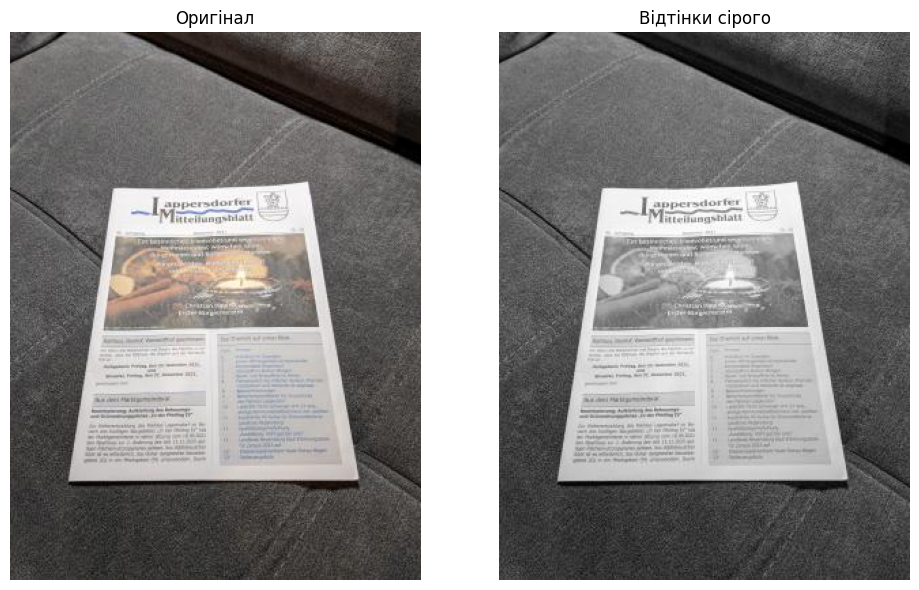

In [ ]:
img = cv2.imread("document.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
rows, cols = gray.shape

plt.subplot(121), plt.imshow(img), plt.title("Оригінал"), plt.axis("off")
plt.subplot(122), plt.imshow(gray, cmap="gray"), plt.title("Відтінки сірого"), plt.axis("off")
plt.tight_layout()
plt.show()

### 2. Кути документа
Використовую координати, отримані алгоритмом із моєї попередньої МКР: детектором Гарріса з порогом −7 і дескрипторами яскравості з `quad_size = 7`. Позначки малюю на копії фотографії.

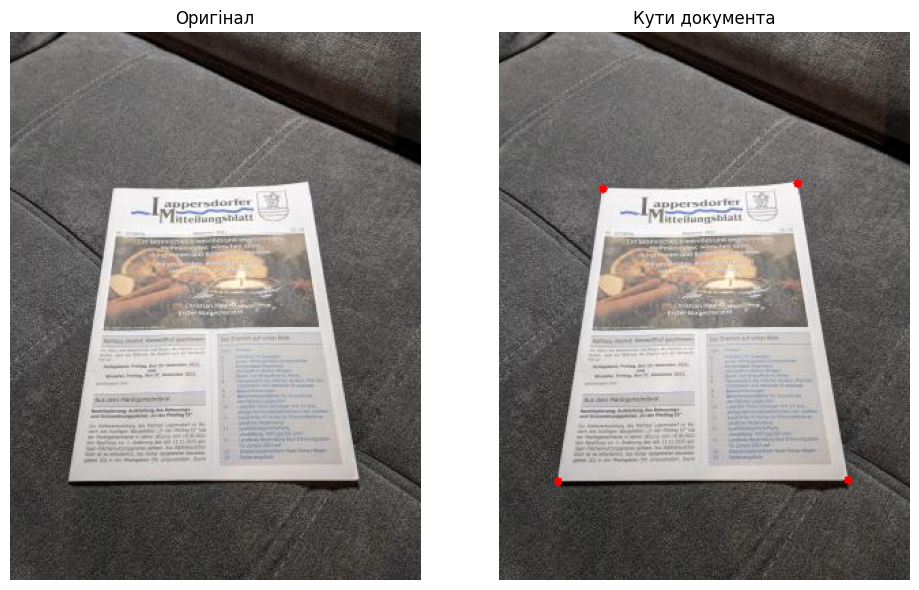

In [3]:
top_left = [76, 115]
top_right = [219, 111]
bottom_left = [43, 330]
bottom_right = [256, 329]

out = img.copy()
for point in [top_left, top_right, bottom_left, bottom_right]:
    cv2.circle(out, tuple(point), 3, (255, 0, 0), -1)

plt.subplot(121), plt.imshow(img), plt.title("Оригінал"), plt.axis("off")
plt.subplot(122), plt.imshow(out), plt.title("Кути документа"), plt.axis("off")
plt.tight_layout()
plt.show()

### 3. Відповідність точок
Переношу кути документа у кути вихідного зображення. В обох масивах дотримуюся одного порядку: верхній лівий, верхній правий, нижній лівий, нижній правий. Розмір результату залишаю таким самим, як у початкової фотографії.

In [4]:
src = np.array([top_left, top_right, bottom_left, bottom_right], dtype=np.float32)
dst = np.array([[0, 0], [cols - 1, 0], [0, rows - 1],
                [cols - 1, rows - 1]], dtype=np.float32)

### 4. Афінне перетворення: перші три точки
Обчислюю матрицю за першими трьома парами точок.

Матриця перетворення:
[[ 2.11397119e+00  3.24469996e-01 -1.97975860e+02]
 [ 5.25267043e-02  1.87782968e+00 -2.19942443e+02]]


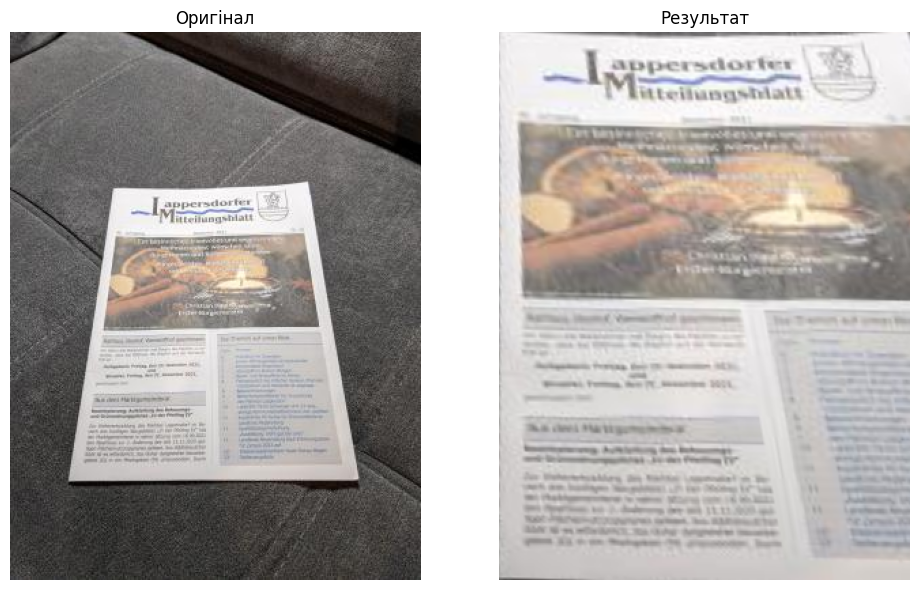

In [5]:
M = cv2.getAffineTransform(src[:3], dst[:3])
affine_first = cv2.warpAffine(img, M, (cols, rows))
print("Матриця перетворення:")
print(M)

plt.subplot(121), plt.imshow(img), plt.title("Оригінал"), plt.axis("off")
plt.subplot(122), plt.imshow(affine_first), plt.title("Результат"), plt.axis("off")
plt.tight_layout()
plt.show()

Три вибрані кути переходять у задані точки, але четвертий кут не збігається з потрібним. Документ залишається спотвореним.

### 5. Афінне перетворення: останні три точки
Повторюю перетворення за останніми трьома парами точок.

Матриця перетворення:
[[ 1.41202040e+00 -2.39654839e-01  1.83692195e+01]
 [ 8.65055626e-03  1.84256848e+00 -2.06419573e+02]]


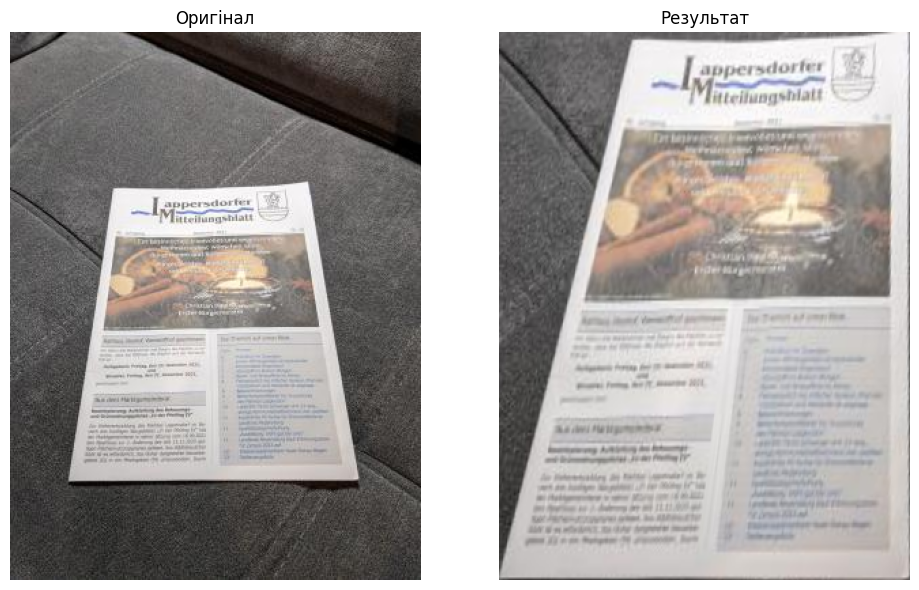

In [6]:
M = cv2.getAffineTransform(src[1:], dst[1:])
affine_last = cv2.warpAffine(img, M, (cols, rows))
print("Матриця перетворення:")
print(M)

plt.subplot(121), plt.imshow(img), plt.title("Оригінал"), plt.axis("off")
plt.subplot(122), plt.imshow(affine_last), plt.title("Результат"), plt.axis("off")
plt.tight_layout()
plt.show()

Зміна трійки точок змінює результат, але не усуває перспективу: тепер не узгоджується кут, який не входив до цієї трійки.

### 6. Оцінювання афінного перетворення
Передаю всі чотири пари точок до estimateAffine2D. RANSAC визначає, які відповідності узгоджуються з афінною моделлю.

Матриця перетворення:
[[ 2.09494924e+00 -3.55564779e-01 -1.18326192e+02]
 [ 5.13377179e-02  1.83532341e+00 -2.14963859e+02]]
Inliers: [1 1 0 1]


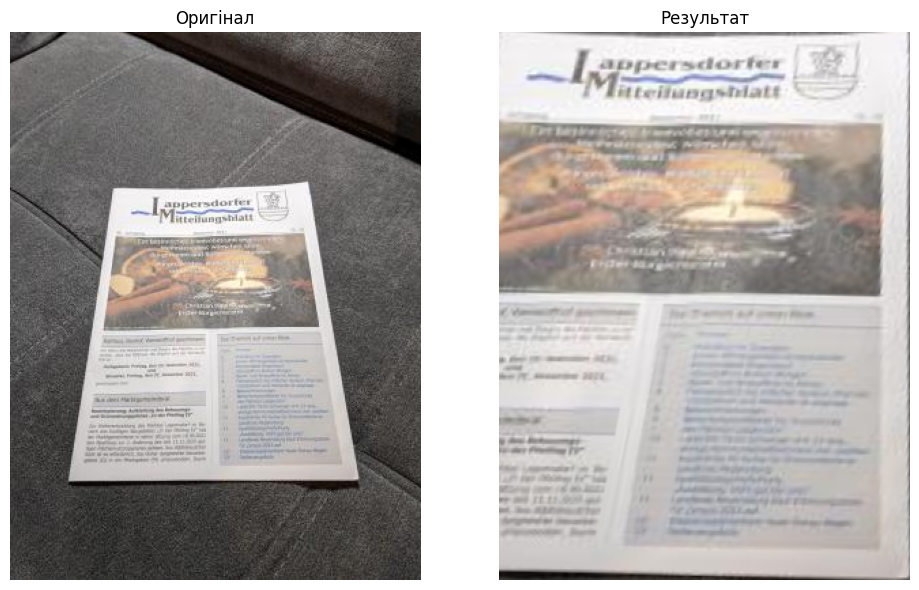

In [7]:
M, inliers = cv2.estimateAffine2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
affine_estimated = cv2.warpAffine(img, M, (cols, rows))
print("Матриця перетворення:")
print(M)
print("Inliers:", inliers.ravel())

plt.subplot(121), plt.imshow(img), plt.title("Оригінал"), plt.axis("off")
plt.subplot(122), plt.imshow(affine_estimated), plt.title("Результат"), plt.axis("off")
plt.tight_layout()
plt.show()

Отримала `inliers = [1, 1, 0, 1]`: RANSAC прийняв верхній лівий, верхній правий і нижній правий кути, а нижній лівий відхилив. Значення 1 означає прийняту відповідність, а 0 — відхилену. Причина тут у тому, що афінна модель не може точно врахувати перспективне спотворення всіх чотирьох кутів. 

### 7. Перспективне перетворення
Обчислюю гомографію за всіма чотирма парами точок та застосовую її до документа.

Матриця перетворення:
[[ 2.96021029e+00  4.54357858e-01 -2.77227135e+02]
 [ 1.07463050e-01  3.84180405e+00 -4.49974657e+02]
 [ 2.37188082e-04  3.13841065e-03  1.00000000e+00]]


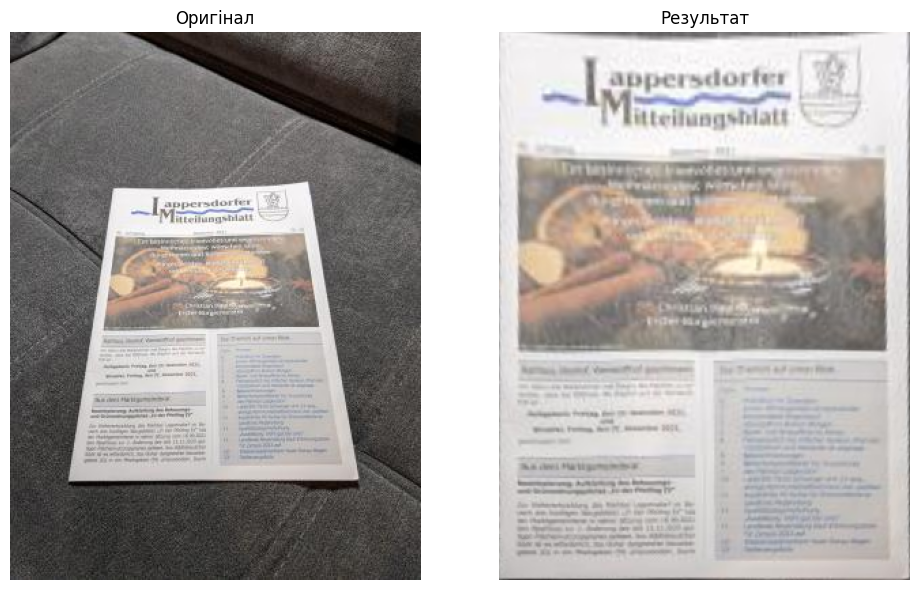

In [8]:
M = cv2.getPerspectiveTransform(src, dst)
perspective = cv2.warpPerspective(img, M, (cols, rows))
print("Матриця перетворення:")
print(M)

plt.subplot(121), plt.imshow(img), plt.title("Оригінал"), plt.axis("off")
plt.subplot(122), plt.imshow(perspective), plt.title("Результат"), plt.axis("off")
plt.tight_layout()
plt.show()

Гомографія переносить усі чотири кути у задані позиції. Документ заповнює прямокутне зображення, а більшість фону зникає.

### 8. Порівняння результатів

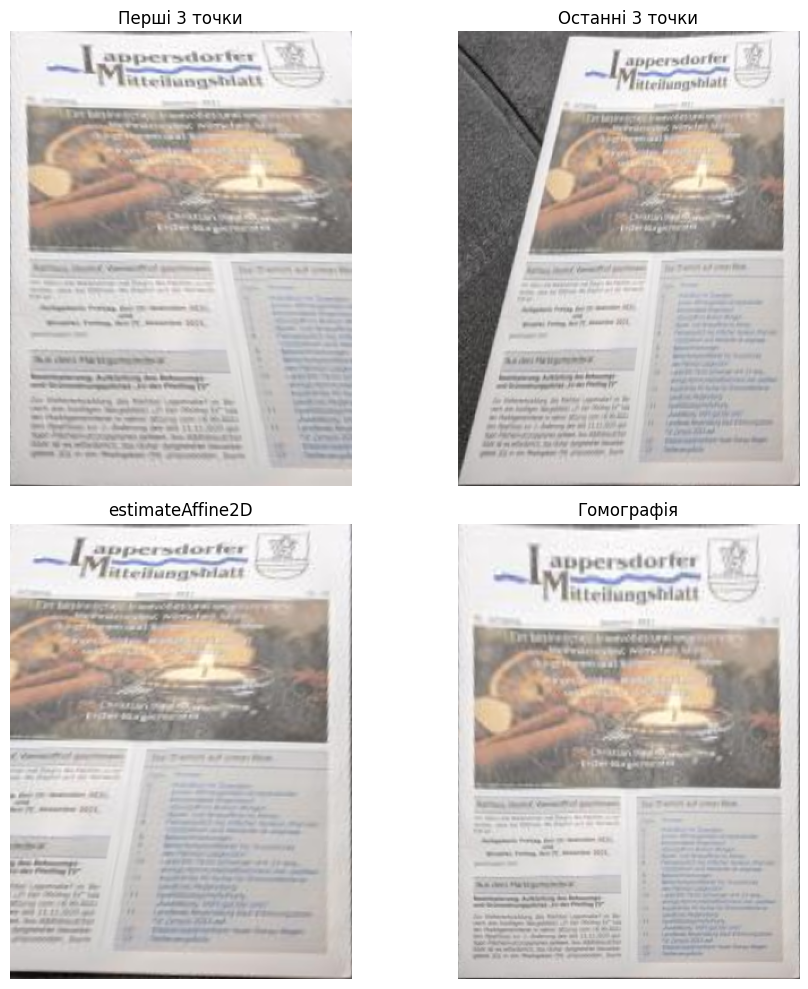

In [9]:
images = [affine_first, affine_last, affine_estimated, perspective]
titles = ["Перші 3 точки", "Останні 3 точки", "estimateAffine2D", "Гомографія"]
plt.figure(figsize=(10, 10))
for i, (image, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2, 2, i)
    plt.imshow(image)
    plt.title(title)
    plt.axis("off")
plt.tight_layout()
plt.show()

### 9. Відповіді на питання

**1. Чому афінне перетворення працює недостатньо добре?**
Афінне перетворення зберігає паралельність прямих. На фотографії через перспективу документ має форму трапеції, тому одним афінним перетворенням не можна точно перенести всі чотири кути в кути прямокутника.

**2. Що означають значення вектора inliers?**
Значення 1 позначає пару точок, яка узгоджується з отриманою матрицею в межах заданого порога, а 0 — пару, яку RANSAC відхилив. У цій роботі чотири кути не узгоджуються з однією афінною моделлю, тому відхилена точка не обов’язково визначена неправильно.

**3. Як виглядає результат гомографії?**
Гомографія краще вирівнює документ, бо враховує перспективне спотворення та використовує всі чотири кути. Межі документа переходять у межі прямокутника. Водночас перетворення не відновлює втрачену чіткість тексту, а точні фізичні пропорції аркуша не гарантовані, оскільки його справжній розмір не задано.

### Висновок
Я порівняла три варіанти афінного перетворення та гомографію. Для цієї фотографії найкраще підходить перспективне перетворення, яке дозволяє вирівняти документ за всіма чотирма кутами.